# Data analysis: `data/clean/data.csv`

Only this file is analysed. Every model (median baseline, linear, ridge, NN) trains on it through
`engines.common.load_splits`, so a problem here caps all of them.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

LAB = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "engines" / "common.py").exists())
sys.path.insert(0, str(LAB))
from engines.common import load_splits, load_config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

BLUE, LIGHT_BLUE, RED, GRAY, INK, INK2 = "#257de0", "#cce3fd", "#ec4647", "#d9d9d9", "#191919", "#666666"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#eeeeee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
})
usd = mtick.FuncFormatter(lambda v, _: f"${v:,.0f}")

cfg = load_config()
dc = cfg["data"]
TARGET = dc["target"]
d = pd.read_csv(LAB / dc["path"], encoding="utf-8-sig", low_memory=False)
FEATURES = [c for c in d.columns if c != TARGET]
d["ppm2"] = d[TARGET] / d["area_m2"]
d["log_price"] = np.log(d[TARGET])
print(f"{dc['path']}: {len(d):,} rows, {len(FEATURES)} features")
print("null cells:", int(d[FEATURES].isna().sum().sum()))

data/clean/data.csv: 12,491 rows, 24 features
null cells: 0


## 1. Shape and types

In [2]:
summary = d.groupby("property_type").agg(
    n=(TARGET, "size"), price_median=(TARGET, "median"), area_median=("area_m2", "median"),
    ppm2_median=("ppm2", "median")).sort_values("n", ascending=False)
summary["share"] = (summary["n"] / len(d)).map("{:.1%}".format)
order = summary.index.tolist()
summary.round(0)

,n,price_median,area_median,ppm2_median,share
property_type,,,,,
Condo,5369,90000.0,60.0,1538.0,43.0%
Villa,2279,440000.0,299.0,1705.0,18.2%
Flat,1510,125000.0,90.0,1333.0,12.1%
House,1313,160000.0,119.0,1214.0,10.5%
Shophouse,1190,265000.0,100.0,2532.0,9.5%
Twin Villa,468,300000.0,176.0,1717.0,3.7%
Link House,346,140000.0,94.0,1576.0,2.8%
Land,16,235000.0,237.0,1093.0,0.1%


- Condo is 43% of rows; **Land has only 16 rows**: too few to learn, and `evaluate` skips groups under 10 test rows anyway.
- 95% of rows are Phnom Penh (section 8).

## 2. Target: `price_usd`

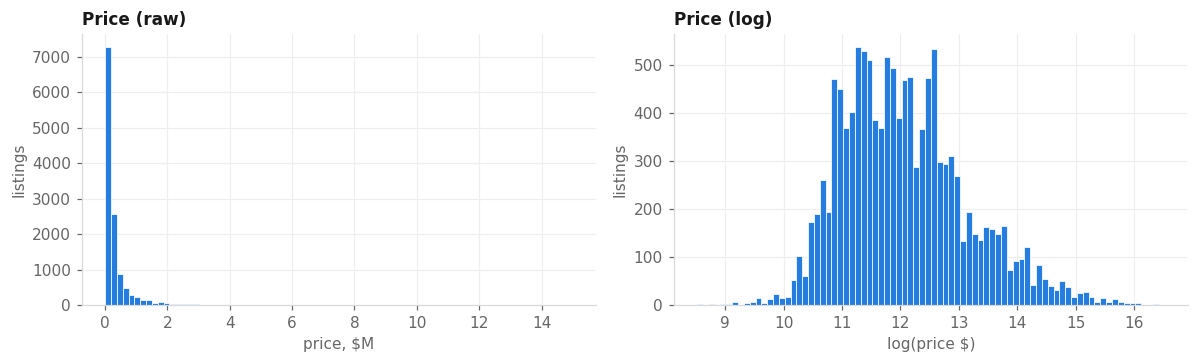

skew raw 7.25   skew log 0.63
count        12,491
mean        358,373
std         717,675
min           5,000
1%           25,000
5%           39,500
50%         155,000
95%       1,350,000
99%       3,534,000
max      15,000,000


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(d[TARGET] / 1e6, bins=80, color=BLUE, edgecolor="white", linewidth=0.5)
ax[0].set(title="Price (raw)", xlabel="price, $M", ylabel="listings")
ax[1].hist(d["log_price"], bins=80, color=BLUE, edgecolor="white", linewidth=0.5)
ax[1].set(title="Price (log)", xlabel="log(price $)", ylabel="listings")
plt.tight_layout(); plt.show()
print(f"skew raw {d[TARGET].skew():.2f}   skew log {d['log_price'].skew():.2f}")
print(d[TARGET].describe(percentiles=[.01, .05, .5, .95, .99]).map("{:,.0f}".format).to_string())

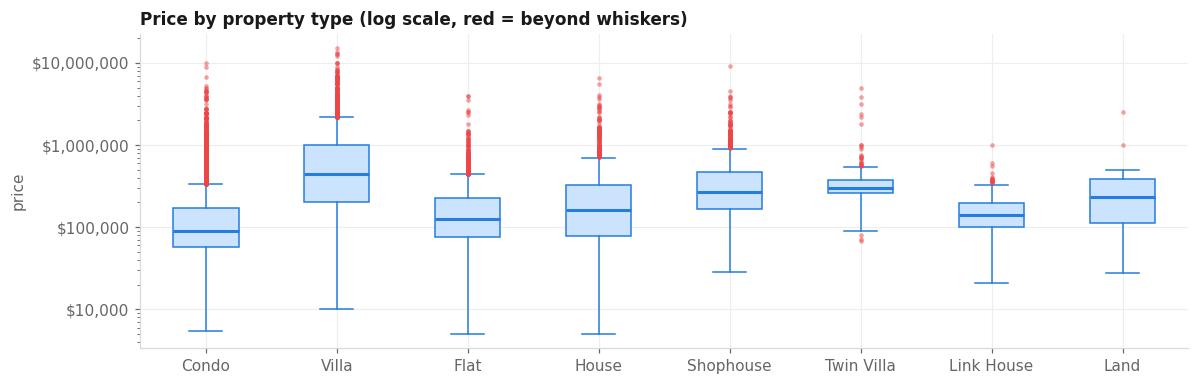

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.boxplot([d.loc[d.property_type == t, TARGET] for t in order], tick_labels=order, widths=0.5,
           patch_artist=True, boxprops=dict(facecolor=LIGHT_BLUE, edgecolor=BLUE), medianprops=dict(color=BLUE, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=RED, markeredgecolor="none", alpha=0.5))
ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
ax.set(title="Price by property type (log scale, red = beyond whiskers)", ylabel="price")
plt.tight_layout(); plt.show()

Raw price is very right-skewed (skew ≈ 7). Models already train on log price, good. But **R² in the comparison is
computed in USD**, so a handful of $3M–$15M listings dominate it (section 9).

## 3. Missing values and imputation

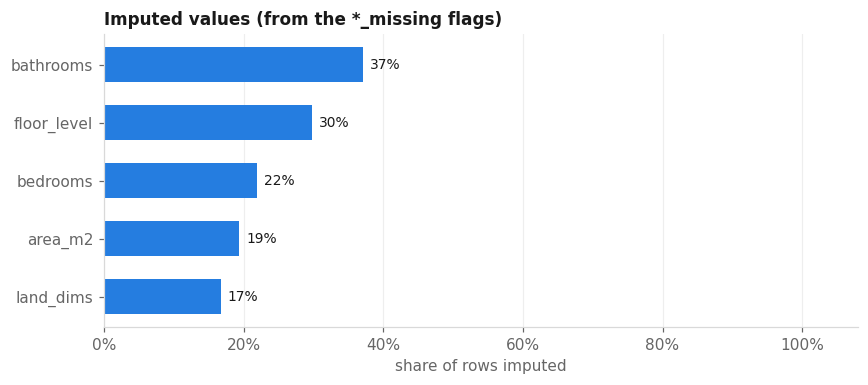

In [5]:
flags = [c for c in d.columns if c.endswith("_missing")]
miss = d[flags].mean().sort_values()
miss.index = [c.replace("_missing", "") for c in miss.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(miss.index, miss.values, color=BLUE, height=0.6)
for y, v in enumerate(miss.values):
    ax.text(v + 0.01, y, f"{v:.0%}", va="center", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1.08)
ax.set(title="Imputed values (from the *_missing flags)", xlabel="share of rows imputed")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [6]:
imputed_by_type = d.groupby("property_type")[flags].mean().mul(100).round(1)
imputed_by_type.columns = [c.replace("_missing", "") for c in flags]
print("% of rows imputed, per type")
display(imputed_by_type)

print("Most common imputed values (imputation collapses onto a few numbers):")
for c in ["bedrooms", "bathrooms", "floor_level", "area_m2"]:
    m = d[c + "_missing"] == 1
    top = d.loc[m, c].value_counts().head(3)
    print(f"  {c:12s} {m.sum():5d} imputed; top values {dict(top)}  ({top.sum() / m.sum():.0%} of imputed)")

% of rows imputed, per type


,area_m2,bedrooms,bathrooms,floor_level,land_dims
property_type,,,,,
Condo,8.8,33.9,66.1,69.3,0.0
Flat,40.9,7.9,10.3,0.0,37.2
House,36.4,16.6,16.9,0.0,36.9
Land,68.8,0.0,0.0,0.0,68.8
Link House,9.0,2.3,2.3,0.0,12.7
Shophouse,30.5,16.6,15.9,0.0,29.4
Twin Villa,12.6,10.5,10.5,0.0,16.5
Villa,16.7,14.3,20.5,0.0,24.5


Most common imputed values (imputation collapses onto a few numbers):
  bedrooms      2741 imputed; top values {1.0: np.int64(1076), 2.0: np.int64(562), 4.0: np.int64(417)}  (75% of imputed)
  bathrooms     4639 imputed; top values {1.0: np.int64(1830), 2.0: np.int64(1654), 5.0: np.int64(407)}  (84% of imputed)
  floor_level   3720 imputed; top values {12.0: np.int64(1089), 16.0: np.int64(783), 13.0: np.int64(576)}  (66% of imputed)
  area_m2       2415 imputed; top values {92.0: np.int64(73), 160.0: np.int64(58), 100.0: np.int64(56)}  (8% of imputed)


- `bathrooms` 37% imputed, `bedrooms` 22% (**34% of condos**), `area_m2` 19%, `floor_level` 30%.
- Imputed values pile onto a few numbers. The `*_missing` flags let models discount them, but for
  **`area_m2`, the strongest price driver, 1 row in 5 is a guess**.
- `land_dims_missing` is 17%, but condos (43% of rows) are set to 0 without the flag (section 4).
- `borey_name` is "No Borey" for 82% of rows.

## 4. Structural zeros

In [7]:
condo = d.property_type == "Condo"
print("land_width_m == 0 :", (d.land_width_m == 0).sum(), "rows; exactly the condos:", ((d.land_width_m == 0) == condo).all())
print("floor_level  == 0 :", (d.floor_level == 0).sum(), "rows; exactly the non-condos:", ((d.floor_level == 0) == ~condo).all())
print("bedrooms     == 0 :", d.loc[d.bedrooms == 0, "property_type"].value_counts().to_dict())
nc = d[~condo & (d.land_dims_missing == 0)]
ratio = nc.land_width_m * nc.land_length_m / nc.area_m2
print("non-condo width*length / area_m2 quantiles:", ratio.quantile([.05, .25, .5, .75, .95]).round(2).to_dict())

land_width_m == 0 : 5369 rows; exactly the condos: True
floor_level  == 0 : 7122 rows; exactly the non-condos: True
bedrooms     == 0 : {'Land': 16, 'Condo': 1}
non-condo width*length / area_m2 quantiles: {0.05: 0.57, 0.25: 1.0, 0.5: 1.0, 0.75: 1.0, 0.95: 1.01}


- Condos get `land_width/length = 0` with `land_dims_missing = 0`; houses get `floor_level = 0`. These mean
  "not applicable", not real zeros. NN can learn that from `property_type`; a **single linear slope** across types
  cannot, so the `interact` variant (type × numeric) is the right shape for linear models.
- For non-condos `area_m2` ≈ width × length, i.e. **land area, not built area**. For condos it is unit floor area.
  Same column, two meanings: price per m² is not comparable across those groups.

## 5. Price per m² outliers

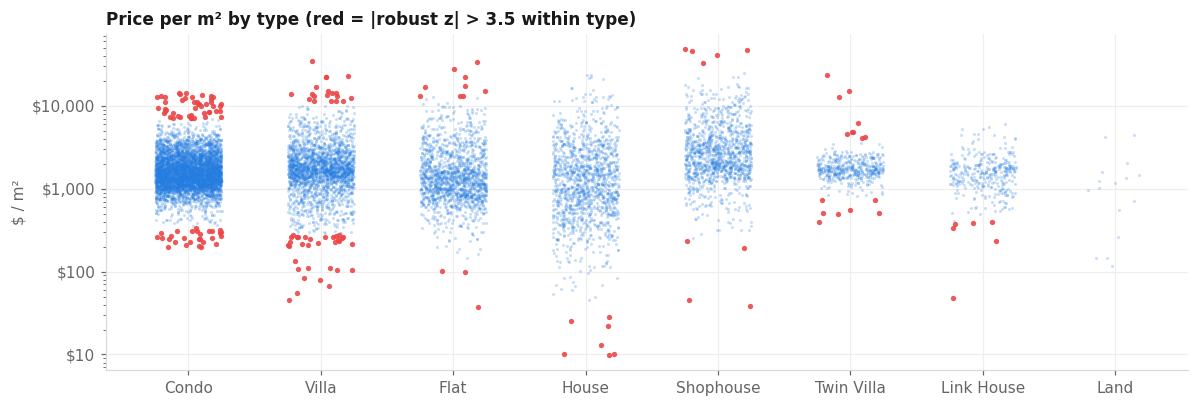

177 outliers (1.4%): {'Condo': 75, 'Flat': 12, 'House': 7, 'Land': 0, 'Link House': 6, 'Shophouse': 9, 'Twin Villa': 16, 'Villa': 52}


In [8]:
log_ppm2 = np.log(d["ppm2"])
med = log_ppm2.groupby(d.property_type).transform("median")
mad = (log_ppm2 - med).abs().groupby(d.property_type).transform("median")
d["ppm2_z"] = (log_ppm2 - med) / (1.4826 * mad)          # robust z-score of log $/m² within type
d["ppm2_outlier"] = d["ppm2_z"].abs() > 3.5

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, t in enumerate(order):
    s = d[d.property_type == t]
    x = i + rng.uniform(-0.25, 0.25, len(s))
    ok = ~s.ppm2_outlier.values
    ax.scatter(x[ok], s.ppm2[ok], s=4, color=BLUE, alpha=0.25, linewidths=0)
    ax.scatter(x[~ok], s.ppm2[~ok], s=12, color=RED, alpha=0.9, linewidths=0)
ax.set_xticks(range(len(order)), order); ax.set_yscale("log"); ax.yaxis.set_major_formatter(usd)
ax.set(title="Price per m² by type (red = |robust z| > 3.5 within type)", ylabel="$ / m²")
plt.tight_layout(); plt.show()
print(f"{d.ppm2_outlier.sum()} outliers ({d.ppm2_outlier.mean():.1%}):", d.ppm2_outlier.groupby(d.property_type).sum().to_dict())

In [9]:
cols = [TARGET, "property_type", "district", "area_m2", "bedrooms", "bathrooms", "area_m2_missing", "ppm2"]
print("Cheapest per m²"); display(d.nsmallest(8, "ppm2")[cols].round(1))
print("Most expensive per m²"); display(d.nlargest(8, "ppm2")[cols].round(1))

Cheapest per m²


,price_usd,property_type,district,area_m2,bedrooms,bathrooms,area_m2_missing,ppm2
2024,25000.0,House,Akreiy Ksatr,2538.0,2.0,2.0,1,9.9
378,15000.0,House,Veal Veaeng,1500.0,3.0,2.0,0,10.0
1864,25500.0,House,Akreiy Ksatr,2538.0,2.0,2.0,1,10.0
9740,123500.0,House,Russey Keo,9366.0,4.0,5.0,0,13.2
3113,56000.0,House,Akreiy Ksatr,2538.0,4.0,5.0,1,22.1
3014,65000.0,House,Akreiy Ksatr,2538.0,2.0,3.0,1,25.6
2564,8500.0,House,Banteay Srei,300.0,2.0,2.0,0,28.3
578,5060.0,Flat,7 Makara,135.0,5.0,4.0,0,37.5


Most expensive per m²


,price_usd,property_type,district,area_m2,bedrooms,bathrooms,area_m2_missing,ppm2
10463,3800000.0,Shophouse,Boeng Keng Kang,79.0,2.0,3.0,1,48101.3
9183,3500000.0,Shophouse,Daun Penh,73.0,4.0,5.0,0,47945.2
10122,560000.0,Shophouse,Daun Penh,12.0,6.0,4.0,0,46666.7
9833,4500000.0,Shophouse,Daun Penh,108.0,18.0,16.0,1,41666.7
10191,12000000.0,Villa,Chroy Changvar,345.0,5.0,6.0,1,34782.6
8913,1200000.0,Flat,Chamkar Mon,35.0,5.0,6.0,0,34285.7
2653,2900000.0,Shophouse,Chamkar Mon,89.0,1.0,1.0,1,32584.3
10177,360000.0,Flat,Tuol Kouk,13.0,13.0,13.0,0,27692.3


Clear data errors at both ends:
- **Too cheap:** houses at 2,538 m² for $25k ($10/m²): land area in the wrong field, or a rural plot listed as "House".
- **Too expensive:** a 35 m² Flat at $1.2M, a 13 m² Flat with 13 bedrooms, a 12 m² Shophouse with 6 bedrooms:
  area is wrong (probably width or floor count parsed into area).

These rows flatten the learned area effect and produce the giant USD errors.

## 6. Suspiciously low prices

In [10]:
low = d[d[TARGET] < 15_000]
print(f"{len(low)} listings under $15k")
display(low[cols].sort_values(TARGET).round(1))

38 listings under $15k


,price_usd,property_type,district,area_m2,bedrooms,bathrooms,area_m2_missing,ppm2
315,5000.0,House,Ta Khmau,72.0,2.0,3.0,1,69.4
578,5060.0,Flat,7 Makara,135.0,5.0,4.0,0,37.5
3958,5500.0,Condo,Sen Sok,24.0,1.0,1.0,0,229.2
3254,5900.0,Condo,Sen Sok,24.0,1.0,1.0,0,245.8
4514,6500.0,Condo,Sen Sok,24.0,1.0,1.0,0,270.8
3593,6500.0,Condo,Sen Sok,24.0,1.0,1.0,0,270.8
4929,6500.0,Condo,Por Senchey,16.0,1.0,1.0,0,406.2
579,8000.0,Flat,7 Makara,80.8,4.0,3.0,1,99.0
3619,8000.0,Condo,Sen Sok,24.0,1.0,1.0,0,333.3
2564,8500.0,House,Banteay Srei,300.0,2.0,2.0,0,28.3


Condos at $5.5k–$9k for 24 m² in Sen Sok, villas at $10k–$14k: likely **deposits / down payments / rent**, not sale
prices. Current floor in the file is $5k.

## 7. Duplicates and train/test leakage

In [11]:
print("exact duplicate rows:", d.duplicated(FEATURES + [TARGET]).sum())
g = d.groupby(FEATURES, dropna=False)[TARGET]
size = g.transform("size")
dup = size > 1
spread = (g.transform("max") / g.transform("min"))[dup]
print(f"rows sharing identical features with another row: {dup.sum():,} ({dup.mean():.1%}) in {(g.size() > 1).sum()} groups")
print("price max/min within those groups:", spread.quantile([.5, .9, .99]).round(2).to_dict())

exact duplicate rows: 22
rows sharing identical features with another row: 2,732 (21.9%) in 912 groups
price max/min within those groups: {0.5: 1.4, 0.9: 3.46, 0.99: 14.0}


In [12]:
# Test rows with an identical-feature twin in train+val, using the exact split the models use.
key = lambda df: df[FEATURES].astype(str).agg("|".join, axis=1)
rows = []
for seed in dc["seeds"]:
    tr, va, te = load_splits(dc["path"], dc["test_size"], dc["val_size"], seed)
    leak = key(te).isin(set(key(pd.concat([tr, va]))))
    rows.append({"seed": seed, "test rows": len(te), "with twin in train": int(leak.sum()), "share": f"{leak.mean():.1%}"})
pd.DataFrame(rows)

,seed,test rows,with twin in train,share
0,42,2499,499,20.0%
1,7,2499,487,19.5%
2,13,2499,470,18.8%
3,21,2499,513,20.5%
4,99,2499,515,20.6%


- About a fifth of rows have an exact feature twin (same listing re-posted, or several units of one project).
- A large share of **test rows have an identical twin in train**, so test scores are optimistic: the model partly
  memorises instead of generalising. Use a **group split** (group = feature hash, or URL/title if kept) or dedupe
  to one row per group (median price).
- Where twins disagree on price (p90 spread ≈ 3.5×, p99 ≈ 14×), at least one is wrong: label noise no model can fit.

## 8. Sparse categories

province      23 values |   12 seen < 5 times | top 'Phnom Penh' = 95%
district      78 values |   44 seen < 5 times | top 'Sen Sok' = 13%
commune      250 values |  117 seen < 5 times | top 'Boeng Keng Kang 1' = 8%
borey_name   181 values |  103 seen < 5 times | top 'No Borey' = 82%
title_deed     5 values |    0 seen < 5 times | top 'Unknown' = 56%
commune: 0 name groups that look like the same place: []
borey_name: 0 name groups that look like the same place: []


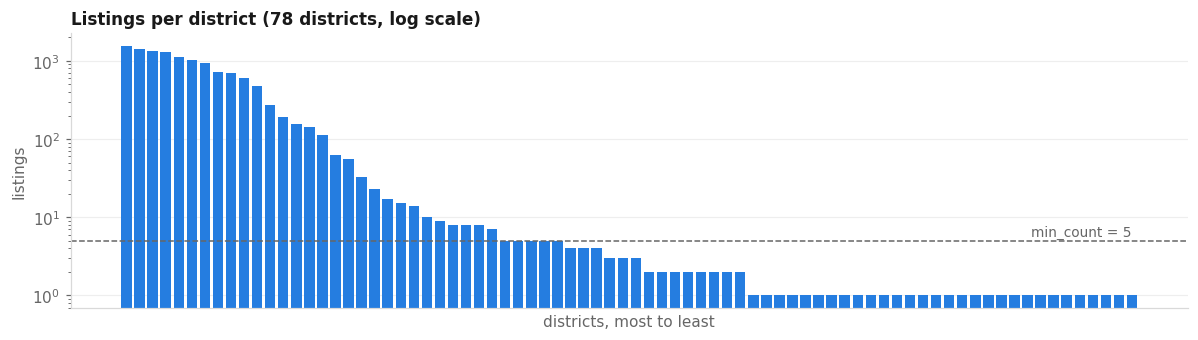

In [13]:
mc = cfg["features"]["min_count"]
for c in ["province", "district", "commune", "borey_name", "title_deed"]:
    vc = d[c].value_counts()
    print(f"{c:11s} {len(vc):4d} values | {(vc < mc).sum():4d} seen < {mc} times | top '{vc.index[0]}' = {vc.iloc[0] / len(d):.0%}")
# spelling variants: names that collide after lower-casing and stripping non-letters
for c in ["commune", "borey_name"]:
    names = pd.Series(d[c].dropna().unique())
    norm = names.str.lower().str.replace(r"[^a-z0-9]", "", regex=True).str.replace("borey", "")
    clash = names.groupby(norm).agg(list)
    clash = clash[clash.map(len) > 1]
    print(f"{c}: {len(clash)} name groups that look like the same place:", clash.head(8).tolist())

fig, ax = plt.subplots(figsize=(11, 3.2))
vc = d["district"].value_counts()
ax.bar(range(len(vc)), vc.values, color=BLUE, width=0.8)
ax.axhline(mc, color=INK2, lw=1, ls="--"); ax.text(len(vc) - 1, mc * 1.15, f"min_count = {mc}", ha="right", color=INK2, fontsize=9)
ax.set_yscale("log"); ax.set_xticks([])
ax.set(title=f"Listings per district ({len(vc)} districts, log scale)", ylabel="listings", xlabel="districts, most to least")
plt.tight_layout(); plt.show()

- `title_deed` is **"Unknown" for 56%**: weak feature.
- Outside Phnom Penh many districts have 1–3 rows and fall into the "other" bucket; predictions there are close to a
  national average. Either scope to Phnom Penh (95% of data) or accept poor provincial accuracy.

## 9. How much a few rows dominate USD metrics

R² and RMSE in USD are sums of squared errors around the mean price. Share of the total sum of squares that comes from
the most expensive listings shows how fragile those metrics are on this data.

In [14]:
y = d[TARGET]
ss = (y - y.mean()) ** 2
top = ss.sort_values(ascending=False)
for n in (10, 50, 125):
    print(f"top {n:4d} rows ({n / len(d):.1%} of data) = {top.iloc[:n].sum() / ss.sum():.0%} of total sum of squares")
print("same in log price: top 125 rows =", f"{((d.log_price - d.log_price.mean()) ** 2).nlargest(125).sum() / ((d.log_price - d.log_price.mean()) ** 2).sum():.0%}")

top   10 rows (0.1% of data) = 20% of total sum of squares
top   50 rows (0.4% of data) = 45% of total sum of squares
top  125 rows (1.0% of data) = 62% of total sum of squares
same in log price: top 125 rows = 10%


A ~1% slice of listings carries a large share of the USD variance, so whichever of them lands in a test split decides
R². That is why R² swings between seeds. Judge models on MdAPE and RMSE-log, and clean the extreme rows above.

## 10. Summary and candidate filters

In [15]:
issues = pd.DataFrame([
    ("Duplicate listings", f"{dup.sum():,} rows in {(g.size() > 1).sum()} groups", "test leakage, label noise", "dedupe or group split"),
    ("Price per m² outliers", f"{d.ppm2_outlier.sum()} rows", "huge USD errors, flat area effect", "drop |robust z| > 3.5 within type"),
    ("Prices < $15k", f"{(d[TARGET] < 15_000).sum()} rows", "likely deposits / rent", "drop or raise floor"),
    ("Land type", f"{(d.property_type == 'Land').sum()} rows", "untrainable group", "drop"),
    ("Imputed area_m2", f"{int(d.area_m2_missing.sum()):,} rows", "key feature is a guess", "compare error with vs without"),
    ("area_m2 meaning differs", "condo = unit, others = land", "$/m² not comparable", "type x area interaction"),
    ("Structural zeros", "condo dims, house floor_level", "linear models mis-fit", "type interactions"),
    ("title_deed Unknown", f"{(d.title_deed == 'Unknown').mean():.0%}", "weak feature", "keep, low expectations"),
    ("Sparse provinces", f"{(d.province != 'Phnom Penh').mean():.0%} outside PP", "poor provincial accuracy", "scope to PP or accept"),
], columns=["issue", "size", "effect", "suggested fix"])
issues

,issue,size,effect,suggested fix
0,Duplicate listings,"2,732 rows in 912 groups","test leakage, label noise",dedupe or group split
1,Price per m² outliers,177 rows,"huge USD errors, flat area effect",drop |robust z| > 3.5 within type
2,Prices < $15k,38 rows,likely deposits / rent,drop or raise floor
3,Land type,16 rows,untrainable group,drop
4,Imputed area_m2,"2,415 rows",key feature is a guess,compare error with vs without
5,area_m2 meaning differs,"condo = unit, others = land",$/m² not comparable,type x area interaction
6,Structural zeros,"condo dims, house floor_level",linear models mis-fit,type interactions
7,title_deed Unknown,56%,weak feature,"keep, low expectations"
8,Sparse provinces,5% outside PP,poor provincial accuracy,scope to PP or accept


In [16]:
def candidate_filter(df):
    """Proposed extra cleaning. Returns (kept rows, drop reason per dropped row). Writes nothing."""
    reason = pd.Series("", index=df.index)
    reason[df.property_type == "Land"] = "land"
    reason[(df[TARGET] < 15_000) & (reason == "")] = "price < 15k"
    reason[df.ppm2_outlier & (reason == "")] = "ppm2 outlier"
    keep = reason == ""
    kept = df[keep].groupby(FEATURES, dropna=False, as_index=False)[TARGET].median()   # one row per twin group
    return kept, reason[~keep]

kept, dropped = candidate_filter(d)
print(dropped.value_counts().to_string())
print(f"after filters + dedupe: {len(d):,} -> {len(kept):,} rows ({1 - len(kept) / len(d):.1%} removed)")

ppm2 outlier    157
price < 15k      38
land             16
after filters + dedupe: 12,491 -> 10,497 rows (16.0% removed)


**Next step:** write the filtered set to e.g. `data/clean/data_filtered.csv`, point `data.path` in
`configs/neural_network_config.yml` at it, rerun the baselines. Models trained on different rows have different test
sets, so compare old vs new on a common (filtered, deduped) test set, not on each run's own numbers.